In [2]:

# =====================================================
# CAMPUSOPTI AI - FEATURE ENGINEERING
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
)
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# Load datasets

faculty = pd.read_csv("../dataset/faculty.csv")
classrooms = pd.read_csv("../dataset/classrooms.csv")
batches = pd.read_csv("../dataset/student_batches.csv")
subjects = pd.read_csv("../dataset/subjects.csv")

batch_subjects = pd.read_csv("../dataset/batch_subjects.csv")
faculty_availability = pd.read_csv("../dataset/faculty_availability.csv")

print("All ML datasets loaded successfully!")


All ML datasets loaded successfully!


In [3]:

# =====================================================
# MERGING DATASETS
# =====================================================

ml_data = batch_subjects.merge(
    batches,
    on="batch_id",
    how="left"
)

ml_data = ml_data.merge(
    subjects[["subject_id", "subject_name"]],
    on="subject_id",
    how="left"
)

faculty_workload = (
    batch_subjects.groupby("faculty_id")
    ["lectures_per_week"].sum()
    .reset_index()
)

faculty_workload.columns = [
    "faculty_id",
    "faculty_weekly_load"
]

faculty_available = (
    faculty_availability.groupby("faculty_id")
    ["available"].sum()
    .reset_index()
)

faculty_available.columns = [
    "faculty_id",
    "faculty_available_slots"
]

ml_data = ml_data.merge(
    faculty_workload,
    on="faculty_id",
    how="left"
)

ml_data = ml_data.merge(
    faculty_available,
    on="faculty_id",
    how="left"
)

# Identify the maximum capacity of a compatible room

room_capacity = (
    classrooms.groupby("room_type")["capacity"]
    .max()
    .reset_index()
)

room_capacity.columns = [
    "required_room_type",
    "available_room_capacity"
]

ml_data = ml_data.merge(
    room_capacity,
    on="required_room_type",
    how="left"
)

# Feature engineering

ml_data["is_lab"] = (
    ml_data["required_room_type"] == "Lab"
).astype(int)

ml_data["capacity_difference"] = (
    ml_data["available_room_capacity"]
    - ml_data["student_count"]
)

display(ml_data.head())

print("ML Dataset Shape:", ml_data.shape)


,batch_id,subject_id,faculty_id,lectures_per_week,required_room_type,department,semester,student_count,subject_name,faculty_weekly_load,faculty_available_slots,available_room_capacity,is_lab,capacity_difference
0,B001,S010,F010,3,Lab,AIDS,3,67,Web Technology,12,25,65,1,-2
1,B001,S008,F008,3,Classroom,AIDS,3,67,Operating Systems,18,27,78,0,11
2,B001,S012,F012,4,Classroom,AIDS,3,67,Software Engineering,12,25,78,0,11
3,B001,S015,F015,3,Classroom,AIDS,3,67,Cyber Security,6,25,78,0,11
4,B001,S003,F003,2,Classroom,AIDS,3,67,DBMS,8,28,78,0,11


ML Dataset Shape: (48, 14)


In [4]:

# =====================================================
# FEATURE SELECTION
# =====================================================

features = [
    "student_count",
    "semester",
    "lectures_per_week",
    "faculty_weekly_load",
    "faculty_available_slots",
    "is_lab"
]

X = ml_data[features].copy()

print("Selected Features:")
display(X.head())

# Check missing values
print("\nMissing Values:")
print(X.isnull().sum())

# Feature scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nFeature Scaling Completed!")
print("Scaled Dataset Shape:", X_scaled.shape)


Selected Features:


,student_count,semester,lectures_per_week,faculty_weekly_load,faculty_available_slots,is_lab
0,67,3,3,12,25,1
1,67,3,3,18,27,0
2,67,3,4,12,25,0
3,67,3,3,6,25,0
4,67,3,2,8,28,0



Missing Values:
student_count              0
semester                   0
lectures_per_week          0
faculty_weekly_load        0
faculty_available_slots    0
is_lab                     0
dtype: int64

Feature Scaling Completed!
Scaled Dataset Shape: (48, 6)


In [5]:

# =====================================================
# MULTIPLE CLUSTERING MODEL COMPARISON
# =====================================================

models = {
    "K-Means": KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ),

    "Agglomerative": AgglomerativeClustering(
        n_clusters=3
    ),

    "DBSCAN": DBSCAN(
        eps=1.5,
        min_samples=4
    ),

    "Gaussian Mixture": GaussianMixture(
        n_components=3,
        random_state=42
    )
}

results = []
model_predictions = {}

for name, model in models.items():

    print("\nTraining Model:", name)

    if name == "Gaussian Mixture":
        labels = model.fit_predict(X_scaled)
    else:
        labels = model.fit_predict(X_scaled)

    model_predictions[name] = labels

    # Exclude DBSCAN noise when calculating its
    # clustering quality metrics.
    valid = labels != -1 if name == "DBSCAN" else np.ones(len(labels), dtype=bool)

    valid_labels = labels[valid]
    valid_data = X_scaled[valid]

    n_clusters = len(set(valid_labels))

    if 2 <= n_clusters < len(valid_data):

        silhouette = silhouette_score(
            valid_data,
            valid_labels
        )

        db_score = davies_bouldin_score(
            valid_data,
            valid_labels
        )

    else:
        silhouette = np.nan
        db_score = np.nan

    results.append({
        "Model": name,
        "Clusters": n_clusters,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Score": db_score
    })

    print("Clusters:", n_clusters)
    print("Silhouette Score:", silhouette)
    print("Davies-Bouldin Score:", db_score)

print("\nAll Models Evaluated!")



Training Model: K-Means
Clusters: 3
Silhouette Score: 0.2176242290688604
Davies-Bouldin Score: 1.5436612766097328

Training Model: Agglomerative
Clusters: 3
Silhouette Score: 0.20350093992240825
Davies-Bouldin Score: 1.59558896763828

Training Model: DBSCAN
Clusters: 1
Silhouette Score: nan
Davies-Bouldin Score: nan

Training Model: Gaussian Mixture
Clusters: 3
Silhouette Score: 0.1834014888742482
Davies-Bouldin Score: 1.6158334068305897

All Models Evaluated!


,Model,Clusters,Silhouette Score,Davies-Bouldin Score
0,K-Means,3,0.217624,1.543661
1,Agglomerative,3,0.203501,1.595589
3,Gaussian Mixture,3,0.183401,1.615833
2,DBSCAN,1,NaN,NaN


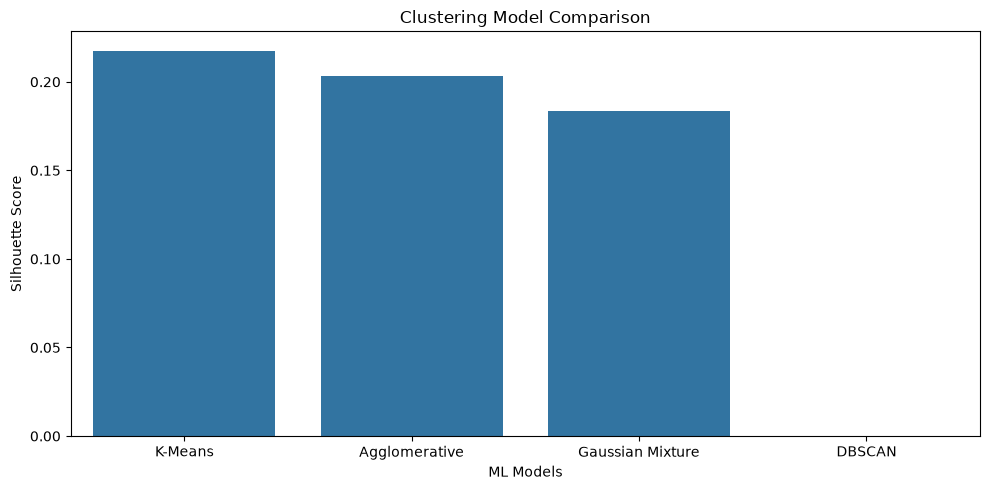

In [6]:

# =====================================================
# MODEL COMPARISON TABLE
# =====================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Silhouette Score",
    ascending=False,
    na_position="last"
)

display(results_df)

# Visual comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Silhouette Score"
)

plt.title("Clustering Model Comparison")
plt.xlabel("ML Models")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()


In [7]:

# =====================================================
# SAVE MODEL RESULTS
# =====================================================

results_df.to_csv(
    "../reports/clustering_model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")


Model comparison results saved successfully!


In [8]:
display(results_df)

,Model,Clusters,Silhouette Score,Davies-Bouldin Score
0,K-Means,3,0.217624,1.543661
1,Agglomerative,3,0.203501,1.595589
3,Gaussian Mixture,3,0.183401,1.615833
2,DBSCAN,1,NaN,NaN


In [9]:

# =====================================================
# K-MEANS - FINAL CLUSTER ASSIGNMENT
# =====================================================

best_model = models["K-Means"]

ml_data["Cluster"] = model_predictions["K-Means"]

print("K-Means Cluster Assignment Completed!")

display(
    ml_data[["batch_id", "subject_name", "Cluster"]].head(15)
)


K-Means Cluster Assignment Completed!


,batch_id,subject_name,Cluster
0,B001,Web Technology,0
1,B001,Operating Systems,0
2,B001,Software Engineering,0
3,B001,Cyber Security,0
4,B001,DBMS,1
5,B001,Computer Networks,0
6,B002,Artificial Intelligence,0
7,B002,Statistics,0
8,B002,Computer Networks,0
9,B002,Operating Systems,0


Number of Records in Each Cluster:
Cluster
0    22
1     7
2    19
Name: count, dtype: int64


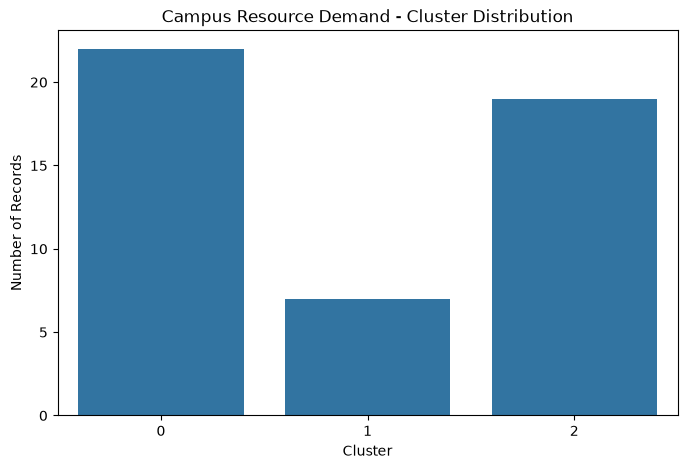

In [10]:

# =====================================================
# CLUSTER DISTRIBUTION
# =====================================================

cluster_counts = ml_data["Cluster"].value_counts().sort_index()

print("Number of Records in Each Cluster:")
print(cluster_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=ml_data,
    x="Cluster"
)

plt.title("Campus Resource Demand - Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")

plt.show()


In [11]:

# =====================================================
# CLUSTER PROFILE ANALYSIS
# =====================================================

cluster_profile = ml_data.groupby("Cluster")[features].mean()

print("Cluster Characteristics:")
display(cluster_profile.round(2))


Cluster Characteristics:


,student_count,semester,lectures_per_week,faculty_weekly_load,faculty_available_slots,is_lab
Cluster,,,,,,
0,62.77,3.77,3.09,12.68,25.36,0.27
1,58.71,4.71,2.00,7.14,27.57,0.43
2,49.05,5.26,3.16,9.84,24.89,0.42


In [12]:

# =====================================================
# SAVE CLUSTER RESULTS
# =====================================================

ml_data.to_csv(
    "../reports/campus_resource_clusters.csv",
    index=False
)

cluster_profile.to_csv(
    "../reports/cluster_profile.csv"
)

print("Cluster analysis results saved successfully!")


Cluster analysis results saved successfully!


In [13]:
display(cluster_profile.round(2))

,student_count,semester,lectures_per_week,faculty_weekly_load,faculty_available_slots,is_lab
Cluster,,,,,,
0,62.77,3.77,3.09,12.68,25.36,0.27
1,58.71,4.71,2.00,7.14,27.57,0.43
2,49.05,5.26,3.16,9.84,24.89,0.42


In [14]:
print(cluster_counts)

Cluster
0    22
1     7
2    19
Name: count, dtype: int64
